<a href="https://colab.research.google.com/github/rakesh-1238987/Salary-Dataset-for-Linear-Regression/blob/main/Salary_Dataset_for_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
from google.colab import files

uploaded = files.upload()

In [4]:
df = pd.read_csv("Salary_Data[1].csv")

df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [5]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

print("\nDataset shape:", df.shape)

Missing values:
YearsExperience    0
Salary             0
dtype: int64

Dataset shape: (30, 2)


In [6]:
# Input: experience-related variable
X = df[['YearsExperience']]

# Output: Salary
y = df['Salary']

print("Input:")
print(X.head())

print("\nTarget:")
print(y.head())

Input:
   YearsExperience
0              1.1
1              1.3
2              1.5
3              2.0
4              2.2

Target:
0    39343.0
1    46205.0
2    37731.0
3    43525.0
4    39891.0
Name: Salary, dtype: float64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 1)
Testing data: (6, 1)


In [8]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
y_pred = model.predict(X_test)

print("Predicted salaries:")
print(y_pred)

Predicted salaries:
[115790.21011287  71498.27809463 102596.86866063  75267.80422384
  55477.79204548  60189.69970699]


In [10]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE  :", mae)
print("RMSE :", rmse)
print("R²   :", r2)

MAE  : 6286.453830757749
RMSE : 7059.04362190151
R²   : 0.9024461774180497


In [11]:
results = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

results

,Actual Salary,Predicted Salary
0,112635.0,115790.210113
1,67938.0,71498.278095
2,113812.0,102596.868661
3,83088.0,75267.804224
4,64445.0,55477.792045
5,57189.0,60189.699707


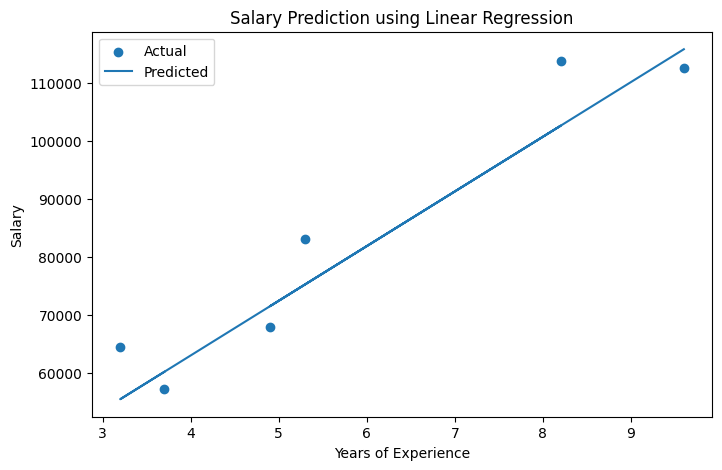

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test, y_pred, label="Predicted")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary Prediction using Linear Regression")

plt.legend()
plt.show()

In [13]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

print(
    f"Salary = {model.coef_[0]:.2f} × YearsExperience "
    f"+ {model.intercept_:.2f}"
)

Slope: 9423.815323030976
Intercept: 25321.583011776813
Salary = 9423.82 × YearsExperience + 25321.58


In [14]:
# Evaluate the model

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("------------------------")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 4))

Model Evaluation Results
------------------------
MAE  : 6286.45
RMSE : 7059.04
R²   : 0.9024
